# Climate Champions: micro:bit Heat Alert Analysis

This notebook examines pre-test and post-test results for the micro:bit
Heat Alert track.

The analysis covers score verification, overall results, participant score
changes, score distributions, question-level performance, and paired
answer transitions.

According to the source workbook, this track uses identical pre/post
questions. This supports comparisons of the same assessment items.

The results describe observed assessment changes. Without a comparison
group, they do not establish that the program alone caused those changes.

In [1]:
from pathlib import Path
from textwrap import fill

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

TRACK = "microbit_heat"
TITLE = "micro:bit Heat Alert"

current = Path.cwd().resolve()

ROOT = next(
    (
        folder
        for folder in [current, *current.parents]
        if (folder / "data" / "processed").is_dir()
    ),
    None
)

if ROOT is None:
    raise FileNotFoundError("Cannot find data/processed.")

DATA = ROOT / "data" / "processed"
FIGURES = ROOT / "outputs" / "figures" / TRACK
TABLES = ROOT / "outputs" / "tables" / TRACK

FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

PRE_COLOR = "#7952B3"
POST_COLOR = "#E88932"

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
})

def save_figure(fig, filename):
    fig.savefig(
        FIGURES / filename,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

print("Project:", ROOT)

Project: C:\Users\User\Desktop\DEVCON-DATA-ANALYTICS\OCTOBER_3_DATA


In [2]:
heat = pd.read_csv(
    DATA / f"{TRACK}.csv",
    dtype={"participant_id": "string"}
)

questions = pd.read_csv(DATA / "question_reference.csv")

heat_keys = questions.loc[
    questions["track"].eq(TRACK)
].copy()

print("Participant records:", len(heat))
print("Answer-key entries:", len(heat_keys))

display(
    heat_keys[
        ["phase", "question", "answer_key_raw", "skill"]
    ].reset_index(drop=True)
)

Participant records: 25
Answer-key entries: 10


,phase,question,answer_key_raw,skill
0,pre,q1,D,Decomposition
1,pre,q2,B,Pattern Recognition
2,pre,q3,C,Abstraction
3,pre,q4,C,Conditional logic / algorithm
4,pre,q5,A,Debugging
5,post,q1,D,Decomposition
6,post,q2,B,Pattern Recognition
7,post,q3,C,Abstraction
8,post,q4,C,Conditional logic / algorithm
9,post,q5,A,Debugging


## 1. Score Verification and Item Comparability

Scores are recalculated using the supplied phase-specific answer keys.
Each correct answer receives one point, for a maximum of five.

The recalculated scores are compared with the workbook values.
Pre/post skill labels, answer keys, and comparability flags are checked
before generating matched-item comparisons.

These checks verify consistency with the supplied reference metadata.
They do not independently verify the original question wording or
answer-key correctness.

In [3]:
if heat.empty:
    raise ValueError("The Heat Alert dataset is empty.")

if heat["participant_id"].isna().any():
    raise ValueError("Missing participant IDs.")

if heat["participant_id"].duplicated().any():
    raise ValueError("Duplicate participant IDs.")

if not heat["track"].eq(TRACK).all():
    raise ValueError("Unexpected track in the dataset.")

expected_keys = {
    (phase, f"q{q}")
    for phase in ["pre", "post"]
    for q in range(1, 6)
}

actual_keys = set(
    heat_keys[["phase", "question"]]
    .itertuples(index=False, name=None)
)

if (
    actual_keys != expected_keys
    or heat_keys.duplicated(["phase", "question"]).any()
):
    raise ValueError("Missing or duplicate answer-key entries.")

identical_flags = (
    heat_keys["identical_pre_post_items"]
    .astype("string")
    .str.strip()
    .str.lower()
)

if not identical_flags.eq("true").all():
    raise ValueError("Reference does not confirm identical pre/post items.")

pre_keys = (
    heat_keys.loc[heat_keys["phase"].eq("pre")]
    .set_index("question")
    .sort_index()
)

post_keys = (
    heat_keys.loc[heat_keys["phase"].eq("post")]
    .set_index("question")
    .sort_index()
)

for column in ["answer_key_raw", "skill"]:
    pre_values = pre_keys[column].astype("string").str.strip()
    post_values = post_keys[column].astype("string").str.strip()

    if not pre_values.eq(post_values).all():
        raise ValueError(f"Pre/post reference mismatch: {column}")

item_rows = []

for phase in ["pre", "post"]:
    correct_columns = []

    for q in range(1, 6):
        question = f"q{q}"
        answer_column = f"{phase}_{question}"

        key_row = heat_keys.loc[
            heat_keys["phase"].eq(phase)
            & heat_keys["question"].eq(question)
        ].iloc[0]

        correct_answer = str(key_row["answer_key_raw"]).strip().upper()

        answers = (
            heat[answer_column]
            .astype("string")
            .str.strip()
            .str.upper()
        )

        if correct_answer not in {"A", "B", "C", "D"}:
            raise ValueError(f"Unresolved key: {phase} {question}")

        if not answers.isin(["A", "B", "C", "D"]).all():
            raise ValueError(f"Unresolved answers: {answer_column}")

        correct_column = f"{phase}_{question}_correct"

        heat[correct_column] = answers.eq(correct_answer).astype(int)
        correct_columns.append(correct_column)

        item_rows.append({
            "phase": phase,
            "question": question,
            "skill": key_row["skill"],
            "n_answered": len(answers),
            "n_correct": int(heat[correct_column].sum()),
            "correct_rate_pct": heat[correct_column].mean() * 100
        })

    heat[f"{phase}_correct"] = heat[correct_columns].sum(axis=1)
    heat[f"{phase}_score_pct"] = heat[f"{phase}_correct"] * 20

heat["change_points"] = heat["post_correct"] - heat["pre_correct"]
heat["change_pp"] = heat["post_score_pct"] - heat["pre_score_pct"]

items = pd.DataFrame(item_rows)

comparisons = [
    ("pre_correct", "pre_correct_workbook"),
    ("post_correct", "post_correct_workbook"),
    ("pre_score_pct", "pre_score_pct_workbook"),
    ("post_score_pct", "post_score_pct_workbook"),
    ("change_pp", "change_pp_workbook"),
]

verification = pd.DataFrame([
    {
        "check": calculated,
        "matching_records": int(
            np.isclose(heat[calculated], heat[original]).sum()
        ),
        "mismatching_records": int(
            (~np.isclose(heat[calculated], heat[original])).sum()
        )
    }
    for calculated, original in comparisons
])

display(verification)

if verification["mismatching_records"].sum() > 0:
    raise ValueError("Review score discrepancies before continuing.")

print("PASS: recalculated scores match the workbook.")
print("PASS: pre/post reference labels and answer keys match.")

,check,matching_records,mismatching_records
0,pre_correct,25,0
1,post_correct,25,0
2,pre_score_pct,25,0
3,post_score_pct,25,0
4,change_pp,25,0


PASS: recalculated scores match the workbook.
PASS: pre/post reference labels and answer keys match.


## 2. Overall Assessment Results

Means and medians summarize assessment performance.
Standard deviations describe variation among participants.

Percentage scores use a 0–100 scale. One additional correct answer
corresponds to a 20-percentage-point increase.

,phase,participants,mean_correct,median_correct,sd_correct,minimum_correct,maximum_correct,mean_score_pct
0,pre,25,2.36,2.0,0.76,1,4,47.2
1,post,25,2.92,3.0,1.04,1,5,58.4


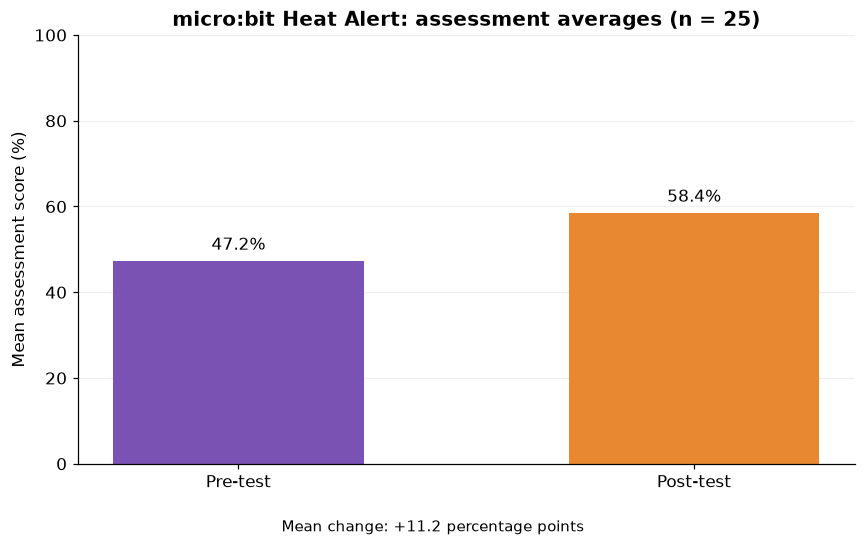

In [4]:
n = len(heat)

summary = pd.DataFrame([
    {
        "phase": phase,
        "participants": n,
        "mean_correct": heat[f"{phase}_correct"].mean(),
        "median_correct": heat[f"{phase}_correct"].median(),
        "sd_correct": heat[f"{phase}_correct"].std(),
        "minimum_correct": heat[f"{phase}_correct"].min(),
        "maximum_correct": heat[f"{phase}_correct"].max(),
        "mean_score_pct": heat[f"{phase}_score_pct"].mean(),
    }
    for phase in ["pre", "post"]
])

pre_mean = heat["pre_score_pct"].mean()
post_mean = heat["post_score_pct"].mean()
mean_change_pp = heat["change_pp"].mean()

display(summary.round(2))

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    ["Pre-test", "Post-test"],
    [pre_mean, post_mean],
    color=[PRE_COLOR, POST_COLOR],
    width=0.55
)

ax.bar_label(
    bars,
    labels=[f"{pre_mean:.1f}%", f"{post_mean:.1f}%"],
    padding=5
)

ax.set_ylim(0, 100)
ax.set_ylabel("Mean assessment score (%)")
ax.set_title(f"{TITLE}: assessment averages (n = {n})")
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.2)

fig.text(
    0.5, 0.02,
    f"Mean change: {mean_change_pp:+.1f} percentage points",
    ha="center", fontsize=10
)

fig.tight_layout(rect=[0, 0.06, 1, 1])
save_figure(fig, "01_microbit_heat_pre_post_averages.png")
plt.show()

## 3. Participant Score Changes

Participants are classified by whether their post-test total was higher,
unchanged, or lower than their pre-test total.

This identifies how individual score changes relate to the group average.
An unchanged total can still involve different answers becoming correct
or incorrect.

,outcome,participants,percent
0,Higher post-test score,13,52.0
1,Unchanged score,8,32.0
2,Lower post-test score,4,16.0


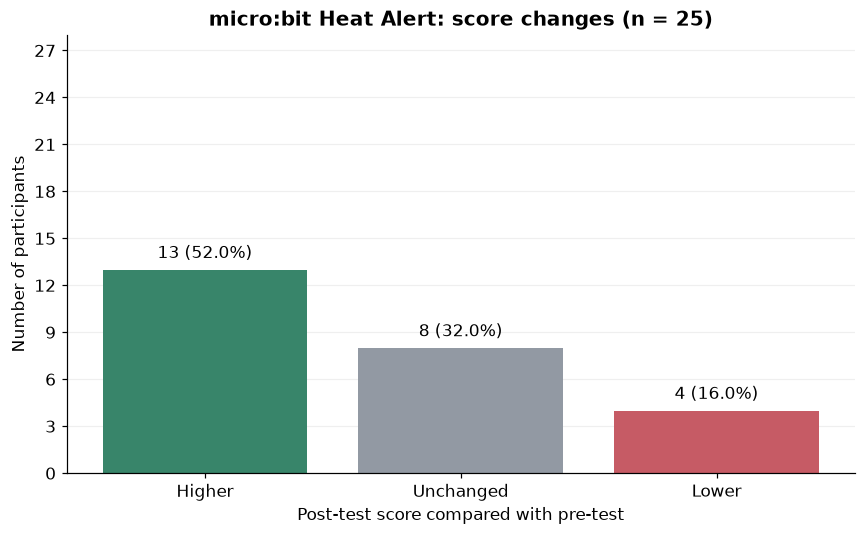

In [5]:
heat["score_change_group"] = np.select(
    [
        heat["change_points"].gt(0),
        heat["change_points"].lt(0)
    ],
    ["Higher post-test score", "Lower post-test score"],
    default="Unchanged score"
)

group_order = [
    "Higher post-test score",
    "Unchanged score",
    "Lower post-test score"
]

change_summary = (
    heat["score_change_group"]
    .value_counts()
    .reindex(group_order, fill_value=0)
    .rename_axis("outcome")
    .reset_index(name="participants")
)

change_summary["percent"] = (
    change_summary["participants"] / n * 100
)

display(change_summary.round(2))

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    ["Higher", "Unchanged", "Lower"],
    change_summary["participants"],
    color=["#38856A", "#9299A3", "#C65B65"]
)

ax.bar_label(
    bars,
    labels=[
        f"{count} ({percent:.1f}%)"
        for count, percent in zip(
            change_summary["participants"],
            change_summary["percent"]
        )
    ],
    padding=5
)

ax.set_ylim(0, n + 3)
ax.set_ylabel("Number of participants")
ax.set_xlabel("Post-test score compared with pre-test")
ax.set_title(f"{TITLE}: score changes (n = {n})")
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.2)

fig.tight_layout()
save_figure(fig, "02_microbit_heat_score_changes.png")
plt.show()

## 4. Score Distributions

Score frequencies show how many participants achieved each total from
zero to five in the pre-test and post-test.

These distributions help distinguish changes in the average from changes
in the overall pattern of scores.

,score,pre_count,post_count
0,0,0,0
1,1,3,2
2,2,11,6
3,3,10,11
4,4,1,4
5,5,0,2


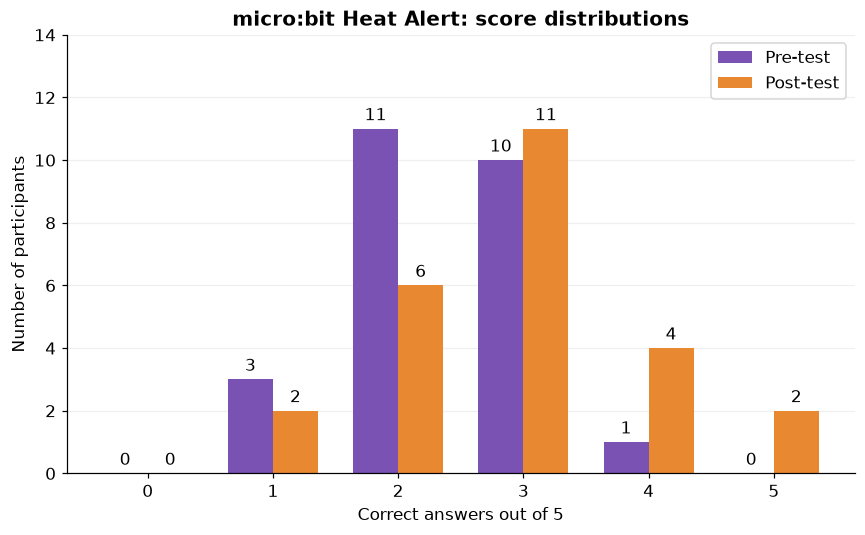

In [6]:
distribution = pd.DataFrame({
    "score": range(6),
    "pre_count": (
        heat["pre_correct"].value_counts()
        .reindex(range(6), fill_value=0).to_numpy()
    ),
    "post_count": (
        heat["post_correct"].value_counts()
        .reindex(range(6), fill_value=0).to_numpy()
    )
})

display(distribution)

fig, ax = plt.subplots(figsize=(8, 5))

x = np.arange(6)
width = 0.36

pre_bars = ax.bar(
    x - width / 2,
    distribution["pre_count"],
    width,
    label="Pre-test",
    color=PRE_COLOR
)

post_bars = ax.bar(
    x + width / 2,
    distribution["post_count"],
    width,
    label="Post-test",
    color=POST_COLOR
)

ax.bar_label(pre_bars, padding=3)
ax.bar_label(post_bars, padding=3)

ax.set_xticks(x)
ax.set_xlabel("Correct answers out of 5")
ax.set_ylabel("Number of participants")
ax.set_title(f"{TITLE}: score distributions")
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set_ylim(
    0,
    max(distribution["pre_count"].max(),
        distribution["post_count"].max()) + 3
)

ax.legend()
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.2)

fig.tight_layout()
save_figure(fig, "03_microbit_heat_score_distributions.png")
plt.show()

## 5. Question-Level Performance

Correct-answer rates are compared for each matched assessment item.
Changes are expressed in percentage points.

The skill labels come from the supplied answer-key reference.
Performance on one item does not establish mastery of the entire skill.

,question,skill,pre_n_correct,pre_correct_rate_pct,post_n_correct,post_correct_rate_pct,change_pp
0,q1,Decomposition,7,28.0,9,36.0,8.0
1,q2,Pattern Recognition,20,80.0,24,96.0,16.0
2,q3,Abstraction,4,16.0,9,36.0,20.0
3,q4,Conditional logic / algorithm,4,16.0,10,40.0,24.0
4,q5,Debugging,24,96.0,21,84.0,-12.0


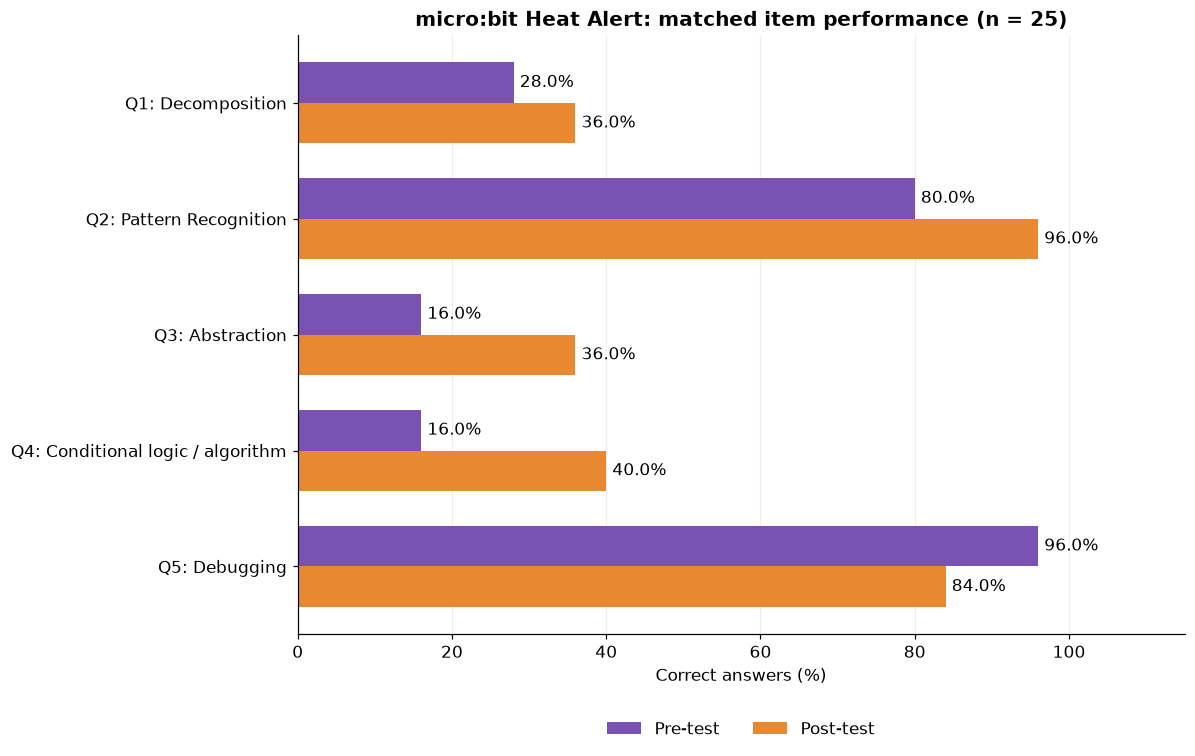

In [7]:
pre_items = (
    items.loc[
        items["phase"].eq("pre"),
        ["question", "skill", "n_correct", "correct_rate_pct"]
    ]
    .rename(columns={
        "n_correct": "pre_n_correct",
        "correct_rate_pct": "pre_correct_rate_pct"
    })
)

post_items = (
    items.loc[
        items["phase"].eq("post"),
        ["question", "n_correct", "correct_rate_pct"]
    ]
    .rename(columns={
        "n_correct": "post_n_correct",
        "correct_rate_pct": "post_correct_rate_pct"
    })
)

item_comparison = (
    pre_items.merge(
        post_items,
        on="question",
        validate="one_to_one"
    )
    .sort_values("question")
    .reset_index(drop=True)
)

item_comparison["change_pp"] = (
    item_comparison["post_correct_rate_pct"]
    - item_comparison["pre_correct_rate_pct"]
)

display(item_comparison.round(2))

labels = [
    fill(f"{row.question.upper()}: {row.skill}", width=40)
    for row in item_comparison.itertuples()
]

y = np.arange(len(item_comparison))
height = 0.35

fig, ax = plt.subplots(figsize=(11, 7))

pre_bars = ax.barh(
    y - height / 2,
    item_comparison["pre_correct_rate_pct"],
    height,
    label="Pre-test",
    color=PRE_COLOR
)

post_bars = ax.barh(
    y + height / 2,
    item_comparison["post_correct_rate_pct"],
    height,
    label="Post-test",
    color=POST_COLOR
)

ax.bar_label(pre_bars, fmt="%.1f%%", padding=4)
ax.bar_label(post_bars, fmt="%.1f%%", padding=4)

ax.set_yticks(y)
ax.set_yticklabels(labels)
ax.invert_yaxis()
ax.set_xlim(0, 115)
ax.set_xticks(np.arange(0, 101, 20))
ax.set_xlabel("Correct answers (%)")
ax.set_title(f"{TITLE}: matched item performance (n = {n})")
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.2)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=2,
    frameon=False
)

fig.tight_layout()
save_figure(fig, "04_microbit_heat_item_performance.png")
plt.show()

## 6. Paired Answer Transitions

Each participant's response to each question is classified as:
- Wrong to right.
- Right to wrong.
- Right both times.
- Wrong both times.

These categories reveal changes that can be hidden by total scores.
The net change in correct responses equals wrong-to-right transitions
minus right-to-wrong transitions.

,question,skill,wrong_to_right,right_to_wrong,right_both,wrong_both,net_correct_change
0,q1,Decomposition,6,4,3,12,2
1,q2,Pattern Recognition,4,0,20,1,4
2,q3,Abstraction,7,2,2,14,5
3,q4,Conditional logic / algorithm,9,3,1,12,6
4,q5,Debugging,0,3,21,1,-3


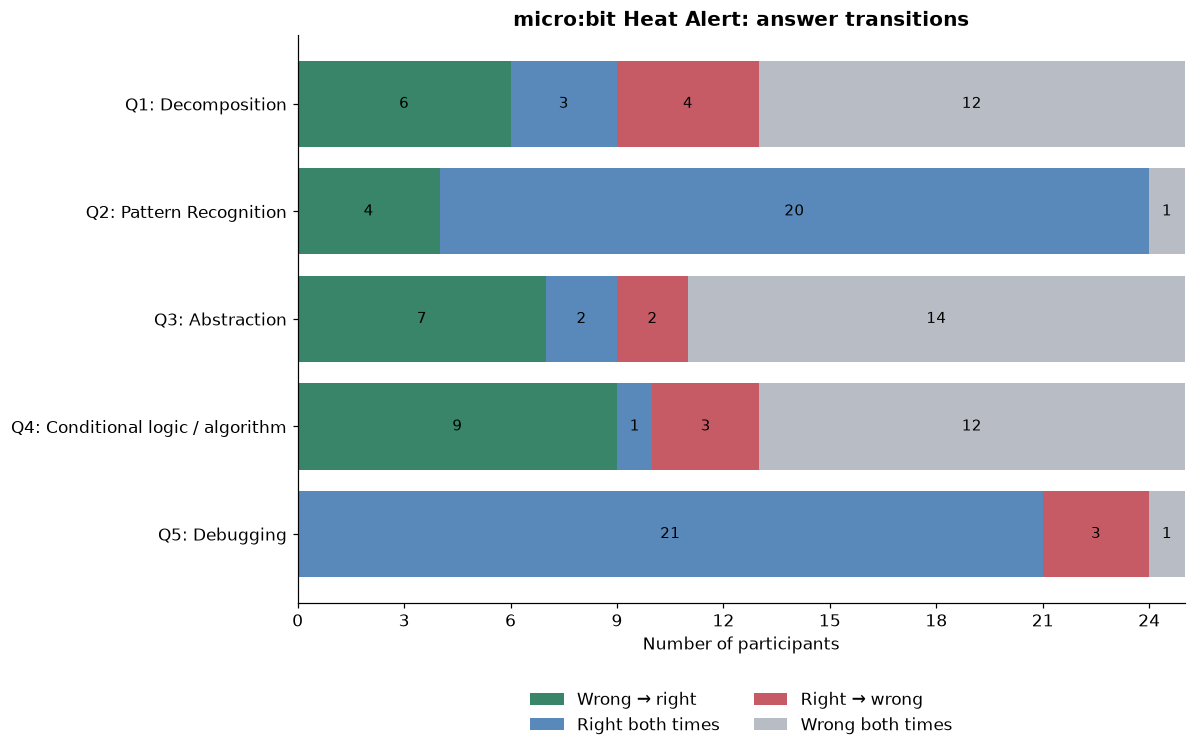

In [8]:
transition_rows = []

for q in range(1, 6):
    question = f"q{q}"

    pre = heat[f"pre_{question}_correct"]
    post = heat[f"post_{question}_correct"]

    transition_rows.append({
        "question": question,
        "skill": pre_keys.loc[question, "skill"],
        "wrong_to_right": int(((pre == 0) & (post == 1)).sum()),
        "right_to_wrong": int(((pre == 1) & (post == 0)).sum()),
        "right_both": int(((pre == 1) & (post == 1)).sum()),
        "wrong_both": int(((pre == 0) & (post == 0)).sum())
    })

transitions = pd.DataFrame(transition_rows)

transition_columns = [
    "wrong_to_right",
    "right_to_wrong",
    "right_both",
    "wrong_both"
]

assert transitions[transition_columns].sum(axis=1).eq(n).all()

transitions["net_correct_change"] = (
    transitions["wrong_to_right"] - transitions["right_to_wrong"]
)

assert np.array_equal(
    transitions["net_correct_change"].to_numpy(),
    (
        item_comparison["post_n_correct"]
        - item_comparison["pre_n_correct"]
    ).to_numpy()
)

display(transitions)

fig, ax = plt.subplots(figsize=(11, 7))

left = np.zeros(len(transitions))

styles = [
    ("wrong_to_right", "Wrong → right", "#38856A"),
    ("right_both", "Right both times", "#5889BA"),
    ("right_to_wrong", "Right → wrong", "#C65B65"),
    ("wrong_both", "Wrong both times", "#B8BDC5"),
]

for column, label, color in styles:
    values = transitions[column].to_numpy()

    bars = ax.barh(
        np.arange(len(transitions)),
        values,
        left=left,
        label=label,
        color=color
    )

    ax.bar_label(
        bars,
        labels=[str(v) if v > 0 else "" for v in values],
        label_type="center",
        fontsize=10
    )

    left += values

ax.set_yticks(np.arange(len(transitions)))
ax.set_yticklabels([
    fill(f"{row.question.upper()}: {row.skill}", width=40)
    for row in transitions.itertuples()
])

ax.invert_yaxis()
ax.set_xlim(0, n)
ax.set_xlabel("Number of participants")
ax.set_title(f"{TITLE}: answer transitions")
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.13),
    ncol=2,
    frameon=False
)

fig.tight_layout()
save_figure(fig, "05_microbit_heat_answer_transitions.png")
plt.show()

In [9]:
highest_post = item_comparison.loc[
    item_comparison["post_correct_rate_pct"].eq(
        item_comparison["post_correct_rate_pct"].max()
    )
]

lowest_post = item_comparison.loc[
    item_comparison["post_correct_rate_pct"].eq(
        item_comparison["post_correct_rate_pct"].min()
    )
]

largest_change = item_comparison.loc[
    item_comparison["change_pp"].eq(
        item_comparison["change_pp"].max()
    )
]

def describe_post(df):
    return "; ".join(
        f"{row.skill}: {row.post_correct_rate_pct:.1f}% "
        f"({row.post_n_correct}/{n})"
        for row in df.itertuples()
    )

def describe_change(df):
    return "; ".join(
        f"{row.skill}: {row.change_pp:+.1f} percentage points"
        for row in df.itertuples()
    )

counts = change_summary.set_index("outcome")["participants"]

pre_high = int(heat["pre_correct"].ge(4).sum())
post_high = int(heat["post_correct"].ge(4).sum())
pre_low = int(heat["pre_correct"].le(2).sum())
post_low = int(heat["post_correct"].le(2).sum())

total_positive = int(transitions["wrong_to_right"].sum())
total_negative = int(transitions["right_to_wrong"].sum())

findings_md = f"""
## Heat Alert Findings

The analysis included **{n} participant records**.
Recalculated scores matched the workbook values for every record.

The mean score changed from **{pre_mean:.1f}%**
({heat['pre_correct'].mean():.2f}/5) to **{post_mean:.1f}%**
({heat['post_correct'].mean():.2f}/5).

The average difference was **{mean_change_pp:+.1f} percentage points**.

### Participant Outcomes

- Higher post-test totals: **{counts['Higher post-test score']}**
  ({counts['Higher post-test score'] / n * 100:.1f}%).
- Unchanged totals: **{counts['Unchanged score']}**
  ({counts['Unchanged score'] / n * 100:.1f}%).
- Lower post-test totals: **{counts['Lower post-test score']}**
  ({counts['Lower post-test score'] / n * 100:.1f}%).

### Score Distribution

The median changed from **{heat['pre_correct'].median():.1f}/5**
to **{heat['post_correct'].median():.1f}/5**.

The number scoring four or five was **{pre_high}**
({pre_high / n * 100:.1f}%) before and **{post_high}**
({post_high / n * 100:.1f}%) after the session.

The number scoring two or fewer was **{pre_low}**
({pre_low / n * 100:.1f}%) before and **{post_low}**
({post_low / n * 100:.1f}%) after the session.

### Question-Level Results

Highest post-test accuracy:
**{describe_post(highest_post)}**.

Lowest post-test accuracy:
**{describe_post(lowest_post)}**.

Largest numerical item change:
**{describe_change(largest_change)}**.

Across **{n * 5} paired participant-question observations**,
there were **{total_positive} wrong-to-right** transitions and
**{total_negative} right-to-wrong** transitions.

These are answer-transition counts, not counts of distinct participants.

### Interpretation Limits

The assessment contains only five items. Results should be interpreted as
performance on those items rather than comprehensive evidence of practical
micro:bit proficiency.

Repeated-question familiarity and guessing may contribute to observed
changes. Without a comparison group, the program's causal effect cannot
be isolated.
"""

display(Markdown(findings_md))


## Heat Alert Findings

The analysis included **25 participant records**.
Recalculated scores matched the workbook values for every record.

The mean score changed from **47.2%**
(2.36/5) to **58.4%**
(2.92/5).

The average difference was **+11.2 percentage points**.

### Participant Outcomes

- Higher post-test totals: **13**
  (52.0%).
- Unchanged totals: **8**
  (32.0%).
- Lower post-test totals: **4**
  (16.0%).

### Score Distribution

The median changed from **2.0/5**
to **3.0/5**.

The number scoring four or five was **1**
(4.0%) before and **6**
(24.0%) after the session.

The number scoring two or fewer was **14**
(56.0%) before and **8**
(32.0%) after the session.

### Question-Level Results

Highest post-test accuracy:
**Pattern Recognition: 96.0% (24/25)**.

Lowest post-test accuracy:
**Decomposition: 36.0% (9/25); Abstraction: 36.0% (9/25)**.

Largest numerical item change:
**Conditional logic / algorithm: +24.0 percentage points**.

Across **125 paired participant-question observations**,
there were **26 wrong-to-right** transitions and
**12 right-to-wrong** transitions.

These are answer-transition counts, not counts of distinct participants.

### Interpretation Limits

The assessment contains only five items. Results should be interpreted as
performance on those items rather than comprehensive evidence of practical
micro:bit proficiency.

Repeated-question familiarity and guessing may contribute to observed
changes. Without a comparison group, the program's causal effect cannot
be isolated.


In [10]:
item_paragraphs = []

for row in item_comparison.itertuples():
    transition = transitions.loc[
        transitions["question"].eq(row.question)
    ].iloc[0]

    item_paragraphs.append(
        f"**{row.question.upper()}: {row.skill}.** "
        f"Correct responses changed from "
        f"{row.pre_n_correct}/{n} ({row.pre_correct_rate_pct:.1f}%) "
        f"to {row.post_n_correct}/{n} "
        f"({row.post_correct_rate_pct:.1f}%), "
        f"a difference of {row.change_pp:+.1f} percentage points. "
        f"{int(transition['wrong_to_right'])} participants changed "
        f"from wrong to right, "
        f"{int(transition['right_to_wrong'])} changed from right to wrong, "
        f"{int(transition['right_both'])} were correct both times, and "
        f"{int(transition['wrong_both'])} were incorrect both times."
    )

item_interpretation_md = (
    "## Detailed Item Interpretation\n\n"
    + "\n\n".join(item_paragraphs)
)

display(Markdown(item_interpretation_md))

## Detailed Item Interpretation

**Q1: Decomposition.** Correct responses changed from 7/25 (28.0%) to 9/25 (36.0%), a difference of +8.0 percentage points. 6 participants changed from wrong to right, 4 changed from right to wrong, 3 were correct both times, and 12 were incorrect both times.

**Q2: Pattern Recognition.** Correct responses changed from 20/25 (80.0%) to 24/25 (96.0%), a difference of +16.0 percentage points. 4 participants changed from wrong to right, 0 changed from right to wrong, 20 were correct both times, and 1 were incorrect both times.

**Q3: Abstraction.** Correct responses changed from 4/25 (16.0%) to 9/25 (36.0%), a difference of +20.0 percentage points. 7 participants changed from wrong to right, 2 changed from right to wrong, 2 were correct both times, and 14 were incorrect both times.

**Q4: Conditional logic / algorithm.** Correct responses changed from 4/25 (16.0%) to 10/25 (40.0%), a difference of +24.0 percentage points. 9 participants changed from wrong to right, 3 changed from right to wrong, 1 were correct both times, and 12 were incorrect both times.

**Q5: Debugging.** Correct responses changed from 24/25 (96.0%) to 21/25 (84.0%), a difference of -12.0 percentage points. 0 participants changed from wrong to right, 3 changed from right to wrong, 21 were correct both times, and 1 were incorrect both times.

In [13]:
priority_skills = "; ".join(
    lowest_post["skill"].astype(str)
)

declining_items = item_comparison.loc[
    item_comparison["change_pp"].lt(0)
]

if declining_items.empty:
    decline_note = (
        "No item had a lower group-level post-test correct-answer rate. "
        "Review any individual right-to-wrong transitions alongside "
        "the group results."
    )
else:
    decline_note = (
        "The following items had lower post-test accuracy: "
        + describe_change(declining_items)
        + ". Review the original questions, answer options, and "
          "response patterns before attributing the declines to a cause."
    )

recommendations_md = """
## Interpretation and recommendations

The average score increased from **47.2% to 58.4%**, a gain of
**11.2 percentage points**. However, improvement varied: 13 participants
improved, eight had unchanged scores, and four scored lower on the post-test.
These results describe observed changes; they do not establish that the
workshop alone caused them.

### Priority areas for reinforcement

- **Decomposition:** Post-test correctness was **36%**. Practise breaking a
  heat-alert system into smaller tasks: reading temperature, checking a
  threshold, and displaying an alert.
- **Abstraction:** Correctness increased from **16% to 36%**, but most
  participants still answered incorrectly. Practise identifying the
  information needed to decide when an alert should activate.
- **Conditional logic / algorithm:** Correctness increased from **16% to
  40%**, the largest item-level gain. Further practice should cover tracing
  if/else decisions for temperatures below, equal to, and above a threshold.

### Review the debugging item

Debugging correctness decreased from **96% to 84%**. Three participants
changed from a correct answer to an incorrect answer, and none changed
from incorrect to correct. Review the question wording and selected
answers before drawing conclusions about why this occurred.

### Build on the strongest result

Pattern recognition reached **96% post-test correctness**, compared with
80% before the workshop. Pattern-recognition activities can provide a
starting point for exercises combining temperature readings, thresholds,
and program decisions.

### Follow-up assessment and prediction

Use a short follow-up assessment to examine whether participants retain
and apply these skills.

For the later machine-learning analysis, treat predictions as exploratory
because this track contains only **25 participants**. Predict post-test
scores using information available before the workshop, evaluate on
participants excluded from model fitting, and compare prediction errors
with simple baselines.
"""

display(Markdown(recommendations_md))


## Interpretation and recommendations

The average score increased from **47.2% to 58.4%**, a gain of
**11.2 percentage points**. However, improvement varied: 13 participants
improved, eight had unchanged scores, and four scored lower on the post-test.
These results describe observed changes; they do not establish that the
workshop alone caused them.

### Priority areas for reinforcement

- **Decomposition:** Post-test correctness was **36%**. Practise breaking a
  heat-alert system into smaller tasks: reading temperature, checking a
  threshold, and displaying an alert.
- **Abstraction:** Correctness increased from **16% to 36%**, but most
  participants still answered incorrectly. Practise identifying the
  information needed to decide when an alert should activate.
- **Conditional logic / algorithm:** Correctness increased from **16% to
  40%**, the largest item-level gain. Further practice should cover tracing
  if/else decisions for temperatures below, equal to, and above a threshold.

### Review the debugging item

Debugging correctness decreased from **96% to 84%**. Three participants
changed from a correct answer to an incorrect answer, and none changed
from incorrect to correct. Review the question wording and selected
answers before drawing conclusions about why this occurred.

### Build on the strongest result

Pattern recognition reached **96% post-test correctness**, compared with
80% before the workshop. Pattern-recognition activities can provide a
starting point for exercises combining temperature readings, thresholds,
and program decisions.

### Follow-up assessment and prediction

Use a short follow-up assessment to examine whether participants retain
and apply these skills.

For the later machine-learning analysis, treat predictions as exploratory
because this track contains only **25 participants**. Predict post-test
scores using information available before the workshop, evaluate on
participants excluded from model fitting, and compare prediction errors
with simple baselines.


In [12]:
tables_to_save = {
    "microbit_heat_score_verification.csv": verification,
    "microbit_heat_score_summary.csv": summary,
    "microbit_heat_change_summary.csv": change_summary,
    "microbit_heat_score_distribution.csv": distribution,
    "microbit_heat_item_performance.csv": items,
    "microbit_heat_item_comparison.csv": item_comparison,
    "microbit_heat_answer_transitions.csv": transitions,
}

for filename, table in tables_to_save.items():
    table.to_csv(TABLES / filename, index=False)

full_findings = "\n\n".join([
    findings_md.strip(),
    item_interpretation_md.strip(),
    recommendations_md.strip()
])

(TABLES / "microbit_heat_findings.md").write_text(
    full_findings,
    encoding="utf-8"
)

print("Saved 5 figures to:", FIGURES)
print("Saved 7 tables and complete findings to:", TABLES)

Saved 5 figures to: C:\Users\User\Desktop\DEVCON-DATA-ANALYTICS\OCTOBER_3_DATA\outputs\figures\microbit_heat
Saved 7 tables and complete findings to: C:\Users\User\Desktop\DEVCON-DATA-ANALYTICS\OCTOBER_3_DATA\outputs\tables\microbit_heat
